# 05 – Attribution factorielle (Fama-French)

Les notebooks précédents montrent que la stratégie momentum **gagne de l'argent**. Mais gagner de l'argent ne prouve pas qu'on a trouvé quelque chose : une stratégie peut simplement être **exposée à des facteurs de risque connus** que le marché rémunère déjà (le marché lui-même, la taille, la *value*, le *momentum*).

On régresse donc les rendements de la stratégie, en excès du taux sans risque, sur ces facteurs :

$$ r_{strat} - r_f = \alpha + \beta_{mkt}(R_m - r_f) + \beta_{smb}\,SMB + \beta_{hml}\,HML + \beta_{mom}\,Mom + \varepsilon $$

- les **bêtas** disent *à quoi* la stratégie est exposée ;
- l'**alpha** est ce qui reste **inexpliqué** par ces expositions. Seul un alpha statistiquement significatif ($|t| > 2$) traduit une vraie compétence.

> **La question** : l'alpha du momentum survit-il quand on contrôle par le facteur momentum académique ?

Prérequis : `python src/ingest.py`, puis `python src/factors.py` (télécharge les facteurs de Kenneth French dans la base), et le module `src/factors.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from analytics import load_prices
from backtest import backtest_momentum
from factors import MODELS, attribution, factor_regression, load_factors

plt.rcParams['figure.figsize'] = (11, 5)
pd.options.display.float_format = '{:.3f}'.format

POS, NEG, MUTED = '#2563eb', '#dc2626', '#9ca3af'  # significatif + / - / non significatif

prices = load_prices(ROOT / 'data' / 'market.duckdb')
factors = load_factors(ROOT / 'data' / 'market.duckdb')
strat = backtest_momentum(prices, frac=0.2, cost_bps=10)['strategy']

overlap = strat.index.intersection(factors.index)
print(f'{len(overlap)} mois communs, du {overlap[0]:%m/%Y} au {overlap[-1]:%m/%Y}')

128 mois communs, du 02/2016 au 09/2026


## 1. Les facteurs

Rendements mensuels des facteurs Fama-French (marché en excès, taille `SMB`, value `HML`, momentum `Mom`) et du taux sans risque `rf`, en décimal. Derniers mois :

In [2]:
factors.tail()

,mkt_rf,smb,hml,mom,rf
date,,,,,
2026-05-31,0.049,-0.016,-0.023,0.014,0.003
2026-06-30,-0.011,0.034,0.036,0.046,0.003
2026-07-31,-0.006,-0.019,0.021,-0.122,0.003
2026-08-31,0.026,0.003,-0.035,-0.056,0.003
2026-09-30,-0.011,-0.032,-0.015,0.067,0.003


Ce sont des portefeuilles *long-short* de référence, construits par Kenneth French sur l'ensemble de la cote américaine. `Mom` achète les gagnantes passées et vend les perdantes : c'est le **benchmark académique** de notre stratégie.

## 2. À quoi la stratégie est-elle exposée ?

Régression complète sur le modèle **FF3 + Mom**. On lit les bêtas (expositions) et leur t-stat (significativité).

In [3]:
excess = (strat - factors['rf']).dropna()
reg = factor_regression(excess, factors[MODELS['FF3+Mom']])
print(f"R2 = {reg.attrs['r2']:.2f}   |   {reg.attrs['n']} mois")
reg

R2 = 0.79   |   128 mois


,coef,se,t_stat
alpha,0.003,0.002,1.520
mkt_rf,1.067,0.052,20.343
smb,0.019,0.087,0.214
hml,-0.043,0.060,-0.727
mom,0.562,0.060,9.411


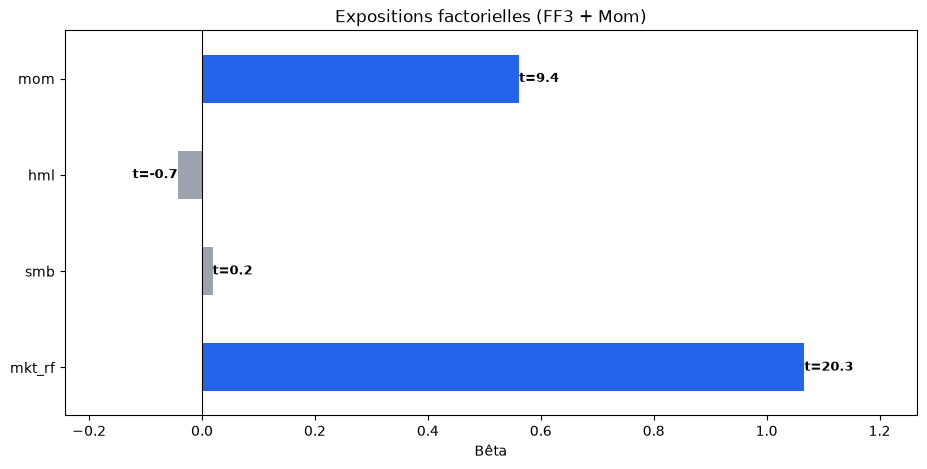

In [4]:
betas = reg.drop('alpha')
colors = [POS if t > 2 else NEG if t < -2 else MUTED for t in betas['t_stat']]
ax = betas['coef'].plot.barh(color=colors)
ax.axvline(0, color='black', linewidth=0.8)
for i, (c, t) in enumerate(zip(betas['coef'], betas['t_stat'])):
    ax.annotate(f't={t:.1f}', (c, i), va='center',
                ha='left' if c >= 0 else 'right', fontsize=9, fontweight='bold')
ax.set(title='Expositions factorielles (FF3 + Mom)', xlabel='Bêta')
ax.margins(x=0.18);

**Lecture.** Deux expositions ressortent nettement. Le **bêta marché** vaut **1,07** ($t=20$) : la stratégie suit le marché presque un pour un — normal pour un portefeuille d'actions *long only*. Surtout, le **bêta momentum** vaut **0,56** ($t=9,4$) : la stratégie est massivement exposée au facteur momentum académique, ce qui est attendu puisqu'elle *est* une stratégie momentum. En revanche `SMB` (0,02) et `HML` (-0,04) sont **insignifiants** une fois `Mom` présent : les petits penchants taille/value vus ailleurs n'étaient qu'un reflet du momentum.

## 3. L'alpha survit-il au contrôle factoriel ?

On empile trois modèles emboîtés — **CAPM** (marché seul), **FF3** (+ taille, value), **FF3 + Mom** (+ momentum) — et on regarde ce que devient l'alpha à mesure qu'on explique mieux les rendements.

In [5]:
attr = attribution(strat, factors)
attr

,alpha_annuel,alpha_tstat,r2,n_mois
modele,,,,
CAPM,0.069,1.924,0.611,128
FF3,0.062,1.774,0.639,128
FF3+Mom,0.041,1.520,0.790,128


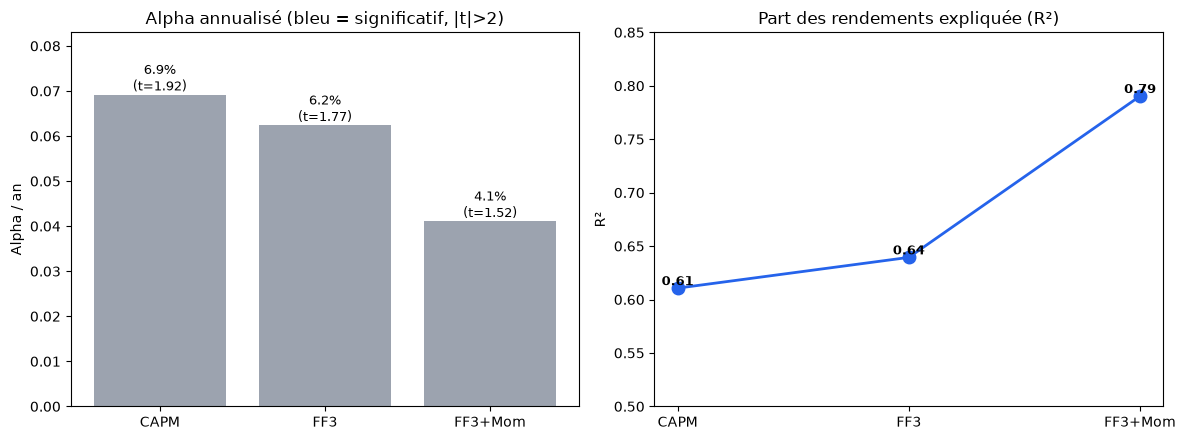

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

colors = [POS if t > 2 else MUTED for t in attr['alpha_tstat']]
ax1.bar(attr.index, attr['alpha_annuel'], color=colors)
for i, (a, t) in enumerate(zip(attr['alpha_annuel'], attr['alpha_tstat'])):
    ax1.annotate(f'{a:.1%}\n(t={t:.2f})', (i, a), ha='center', va='bottom', fontsize=9)
ax1.set(title="Alpha annualisé (bleu = significatif, |t|>2)", ylabel='Alpha / an')
ax1.margins(y=0.2)

ax2.plot(attr.index, attr['r2'], 'o-', color=POS, linewidth=2, markersize=9)
for i, r in enumerate(attr['r2']):
    ax2.annotate(f'{r:.2f}', (i, r), ha='center', va='bottom', fontsize=9, fontweight='bold')
ax2.set(title='Part des rendements expliquée (R²)', ylabel='R²', ylim=(0.5, 0.85))
fig.tight_layout();

**Lecture.** Le verdict est clair. Dès le départ, l'alpha n'est **jamais** vraiment significatif : même sous le CAPM il plafonne à **6,9 %/an** avec $t=1,9$ (sous le seuil de 2). À mesure qu'on ajoute des facteurs, il **s'érode** — 6,9 % → 6,2 % → **4,1 %** — et son $t$ tombe à **1,52**. Au même moment, le **R² bondit de 0,64 à 0,79** quand on introduit `Mom` : ce seul facteur explique une grande part de ce que les autres laissaient dans l'« alpha ». Autrement dit, **l'edge de la stratégie n'est pas une compétence inexpliquée — c'est la prime de risque du momentum**, un facteur connu et réplicable.

## À retenir

- **Pas d'alpha significatif.** À aucun modèle l'alpha n'atteint le seuil $|t|>2$ ; il diminue encore à 4,1 %/an ($t=1,5$) dès qu'on contrôle par le facteur momentum.
- **L'edge est une exposition, pas une compétence.** Bêta `Mom` de 0,56 ($t=9$) et saut du R² à 0,79 : la stratégie *récolte la prime de momentum*, elle ne la bat pas.
- **C'est cohérent et sain.** On retrouve, sur nos 50 actions, exactement ce que la littérature prédit — un bon signe de rigueur, pas une déception : la stratégie capture un facteur réel plutôt qu'un artefact du backtest.
- Limites : facteurs US seulement, **biais du survivant** toujours présent, et un alpha faiblement positif pourrait refléter le secteur (tech) plutôt que du hasard — à creuser avec des facteurs sectoriels.
- Étape 6 — suite possible : **dashboard Streamlit** pour rendre tout ça interactif, et **orchestration Airflow** du pipeline (ingestion → facteurs → backtest).